# H2 Pobudzenie emocji w fazach cyklu

## 1. Konfiguracja

In [1]:
import sys
sys.path.append("..")

import matplotlib.pyplot as plt
import pandas as pd

from src.config import CYCLES, PHASE_COLORS, PHASE_ORDER, PHASES, POLITICAL_SUBREDDITS, PROCESSED_DIR, REFERENCE_SUBREDDITS, RESULTS_DIR

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
VARIABLE = "arousal"

## 2. Wczytanie danych tygodniowych

In [2]:
weekly = pd.read_csv(PROCESSED_DIR / "weekly_emotions.csv", parse_dates=["week_start"])
weekly.shape

(2825, 18)

## 3. Średnia i mediana tygodniowa w fazach

In [3]:
phase_stats = (weekly.dropna(subset=["phase"]).groupby(["camp", "subreddit", "cycle", "phase"])[VARIABLE]
               .agg(mean="mean", median="median", n_weeks="size").reset_index())
phase_stats.to_csv(RESULTS_DIR / "h2_phase_stats.csv", index=False)
phase_stats[phase_stats["subreddit"].isin(POLITICAL_SUBREDDITS)].head(10)

,camp,subreddit,cycle,phase,mean,median,n_weeks
0,dem,Liberal,2012,bazowa,0.779817,0.810436,12
1,dem,Liberal,2012,powyborcza,0.802663,0.800389,8
2,dem,Liberal,2012,przedwyborcza,0.780949,0.783697,64
3,dem,Liberal,2012,przejsciowa,0.792875,0.786907,11
4,dem,Liberal,2012,szczytowa,0.783637,0.784635,9
5,dem,Liberal,2016,bazowa,0.816703,0.828608,19
6,dem,Liberal,2016,powyborcza,0.829355,0.846689,8
7,dem,Liberal,2016,przedwyborcza,0.823177,0.831027,50
8,dem,Liberal,2016,przejsciowa,0.843277,0.832405,11
9,dem,Liberal,2016,szczytowa,0.817759,0.824073,16


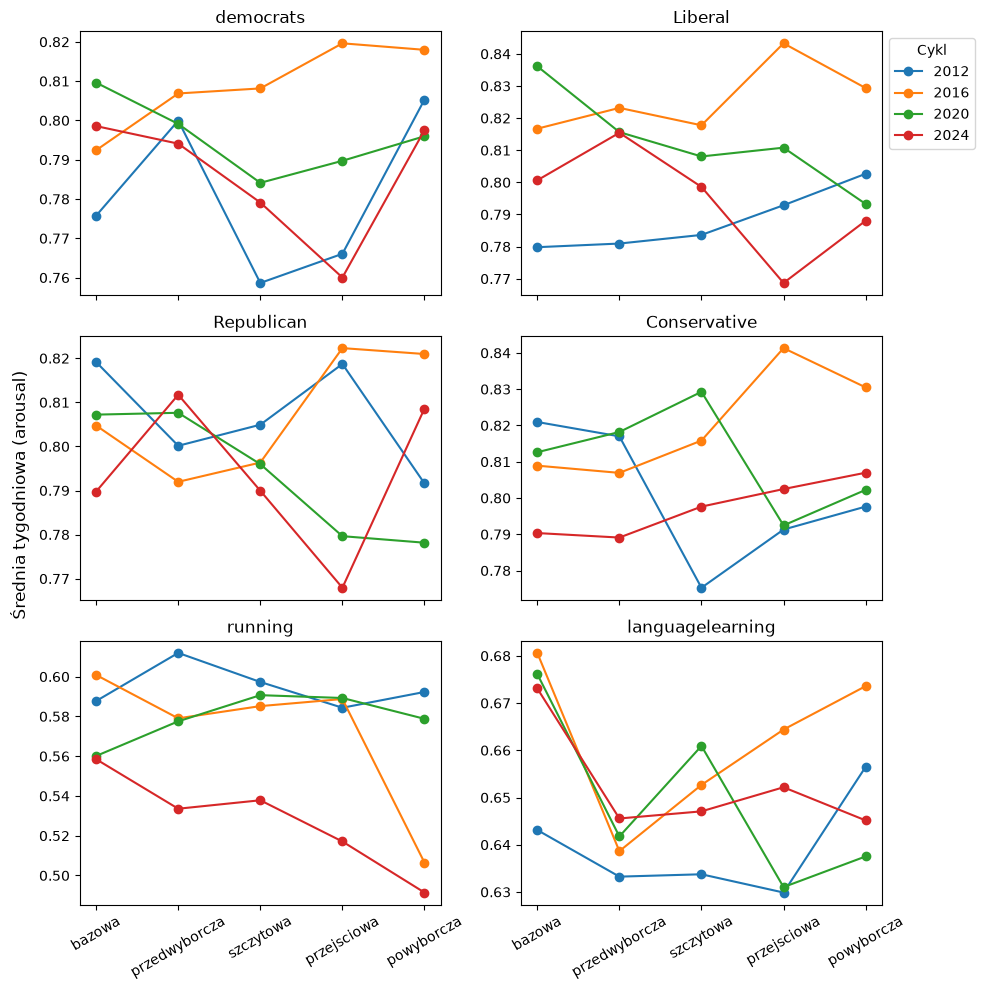

In [4]:
fig, axes = plt.subplots(3, 2, figsize=(10, 10), sharex=True)
for ax, subreddit in zip(axes.ravel(), POLITICAL_SUBREDDITS + REFERENCE_SUBREDDITS):
    for cycle in CYCLES:
        rows = phase_stats[(phase_stats["subreddit"] == subreddit) & (phase_stats["cycle"] == cycle)].set_index("phase").loc[PHASE_ORDER]
        ax.plot(PHASE_ORDER, rows["mean"], marker="o", label=cycle)
    ax.set_title(subreddit)
    ax.tick_params(axis="x", labelrotation=30)
axes[0, 1].legend(title="Cykl", loc="upper left", bbox_to_anchor=(1, 1))
fig.supylabel(f"Średnia tygodniowa ({VARIABLE})")
plt.tight_layout()
plt.show()

## 4. Różnica względem fazy bazowej (główne porównanie: faza szczytowa)

In [5]:
baseline = phase_stats[phase_stats["phase"] == "bazowa"].set_index(["subreddit", "cycle"])[["mean", "median"]]
diff = phase_stats.join(baseline, on=["subreddit", "cycle"], rsuffix="_baseline")
diff["diff_mean"] = diff["mean"] - diff["mean_baseline"]
diff["diff_median"] = diff["median"] - diff["median_baseline"]
diff = diff[diff["phase"].isin(PHASE_ORDER) & (diff["phase"] != "bazowa")]
diff.to_csv(RESULTS_DIR / "h2_diff_vs_baseline.csv", index=False)
peak = diff[diff["phase"] == "szczytowa"].pivot_table(index=["camp", "subreddit"], columns="cycle", values="diff_mean")
peak.round(4)

cycle                         2012    2016    2020    2024
camp      subreddit                                       
dem       Liberal           0.0038  0.0011 -0.0281 -0.0021
          democrats        -0.0171  0.0157 -0.0255 -0.0194
reference languagelearning -0.0094 -0.0280 -0.0152 -0.0260
          running           0.0096 -0.0157  0.0306 -0.0206
rep       Conservative     -0.0457  0.0069  0.0166  0.0073
          Republican       -0.0142 -0.0084 -0.0112  0.0002

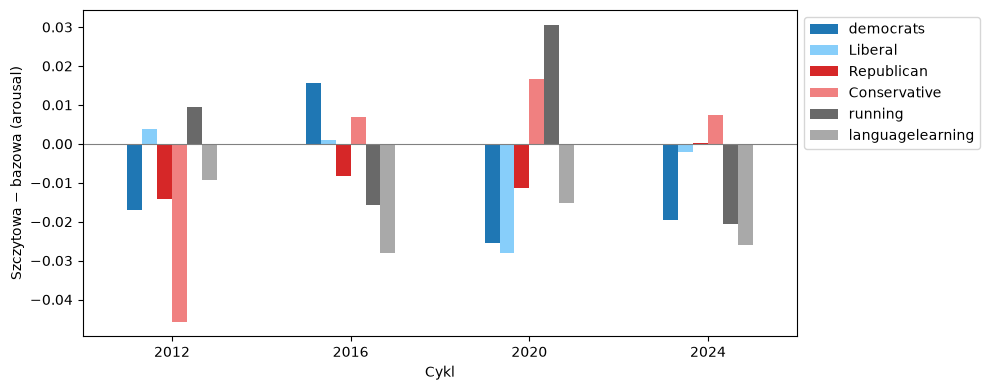

In [6]:
ax = (peak.droplevel("camp").loc[POLITICAL_SUBREDDITS + REFERENCE_SUBREDDITS].T
      .plot.bar(figsize=(10, 4), rot=0, color=["tab:blue", "lightskyblue", "tab:red", "lightcoral", "dimgray", "darkgray"]))
ax.axhline(0, color="gray", linewidth=0.8)
ax.set_xlabel("Cykl")
ax.set_ylabel(f"Szczytowa − bazowa ({VARIABLE})")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

In [7]:
diff_by_phase = diff.pivot_table(index=["subreddit", "cycle"], columns="phase", values="diff_mean")[PHASE_ORDER[1:]].loc[POLITICAL_SUBREDDITS]
diff_by_phase.round(4)

phase               przedwyborcza  szczytowa  przejsciowa  powyborcza
subreddit    cycle                                                   
democrats    2012          0.0242    -0.0171      -0.0097      0.0295
             2016          0.0144     0.0157       0.0272      0.0255
             2020         -0.0105    -0.0255      -0.0199     -0.0136
             2024         -0.0045    -0.0194      -0.0385     -0.0010
Liberal      2012          0.0011     0.0038       0.0131      0.0228
             2016          0.0065     0.0011       0.0266      0.0127
             2020         -0.0205    -0.0281      -0.0253     -0.0429
             2024          0.0148    -0.0021      -0.0320     -0.0126
Republican   2012         -0.0190    -0.0142      -0.0004     -0.0275
             2016         -0.0128    -0.0084       0.0176      0.0162
             2020          0.0004    -0.0112      -0.0276     -0.0291
             2024          0.0220     0.0002      -0.0218      0.0188
Conservative 2012         -0.0040    -0.0457      -0.0296     -0.0233
             2016         -0.0020     0.0069       0.0324      0.0216
             2020          0.0056     0.0166      -0.0202     -0.0104
             2024         -0.0012     0.0073       0.0121      0.0166

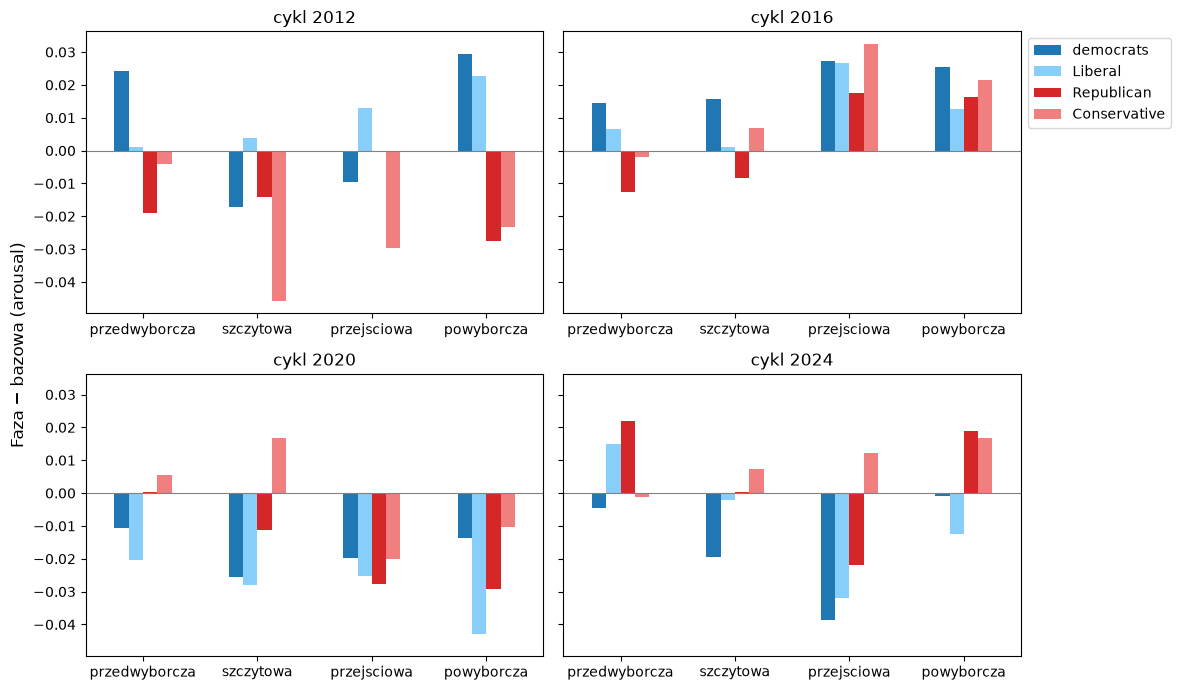

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharey=True)
for ax, cycle in zip(axes.ravel(), CYCLES):
    diff_by_phase.xs(cycle, level="cycle").T.plot.bar(ax=ax, rot=0, legend=False, color=["tab:blue", "lightskyblue", "tab:red", "lightcoral"])
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.set_title(f"cykl {cycle}")
    ax.set_xlabel("")
axes[0, 1].legend(loc="upper left", bbox_to_anchor=(1, 1))
fig.supylabel(f"Faza − bazowa ({VARIABLE})")
plt.tight_layout()
plt.show()

## 5. Faza przedwyborcza osobno dla każdego cyklu

In [9]:
pre_election = diff[diff["phase"] == "przedwyborcza"].pivot_table(index=["camp", "subreddit"], columns="cycle", values="diff_mean")
pre_election.round(4)

cycle                         2012    2016    2020    2024
camp      subreddit                                       
dem       Liberal           0.0011  0.0065 -0.0205  0.0148
          democrats         0.0242  0.0144 -0.0105 -0.0045
reference languagelearning -0.0099 -0.0420 -0.0344 -0.0275
          running           0.0242 -0.0218  0.0174 -0.0249
rep       Conservative     -0.0040 -0.0020  0.0056 -0.0012
          Republican       -0.0190 -0.0128  0.0004  0.0220

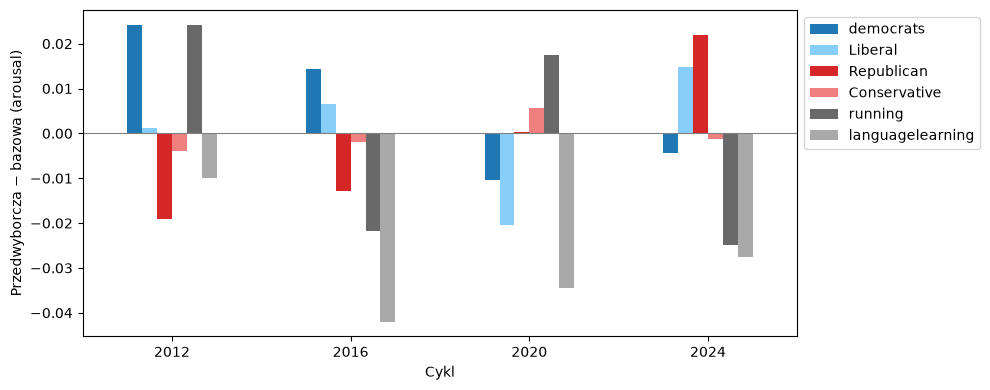

In [10]:
ax = (pre_election.droplevel("camp").loc[POLITICAL_SUBREDDITS + REFERENCE_SUBREDDITS].T
      .plot.bar(figsize=(10, 4), rot=0, color=["tab:blue", "lightskyblue", "tab:red", "lightcoral", "dimgray", "darkgray"]))
ax.axhline(0, color="gray", linewidth=0.8)
ax.set_xlabel("Cykl")
ax.set_ylabel(f"Przedwyborcza − bazowa ({VARIABLE})")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

## 6. Subreddity odniesienia a subreddity polityczne

In [11]:
comparison = diff.groupby(["cycle", "phase", "camp"])["diff_mean"].mean().unstack("camp")
comparison["political_minus_reference"] = (comparison["dem"] + comparison["rep"]) / 2 - comparison["reference"]
comparison.to_csv(RESULTS_DIR / "h2_political_vs_reference.csv")
comparison.round(4)

camp                    dem  reference     rep  political_minus_reference
cycle phase                                                              
2012  powyborcza     0.0262     0.0090 -0.0254                    -0.0086
      przedwyborcza  0.0127     0.0072 -0.0115                    -0.0066
      przejsciowa    0.0017    -0.0083 -0.0150                     0.0016
      szczytowa     -0.0066     0.0001 -0.0299                    -0.0184
2016  powyborcza     0.0191    -0.0507  0.0189                     0.0697
      przedwyborcza  0.0105    -0.0319 -0.0074                     0.0334
      przejsciowa    0.0269    -0.0142  0.0250                     0.0401
      szczytowa      0.0084    -0.0218 -0.0007                     0.0256
2020  powyborcza    -0.0282    -0.0100 -0.0197                    -0.0140
      przedwyborcza -0.0155    -0.0085  0.0030                     0.0022
      przejsciowa   -0.0226    -0.0080 -0.0239                    -0.0153
      szczytowa     -0.0268     0.0077  0.0027                    -0.0197
2024  powyborcza    -0.0068    -0.0475  0.0177                     0.0530
      przedwyborcza  0.0052    -0.0262  0.0104                     0.0340
      przejsciowa   -0.0352    -0.0311 -0.0048                     0.0111
      szczytowa     -0.0108    -0.0233  0.0037                     0.0198

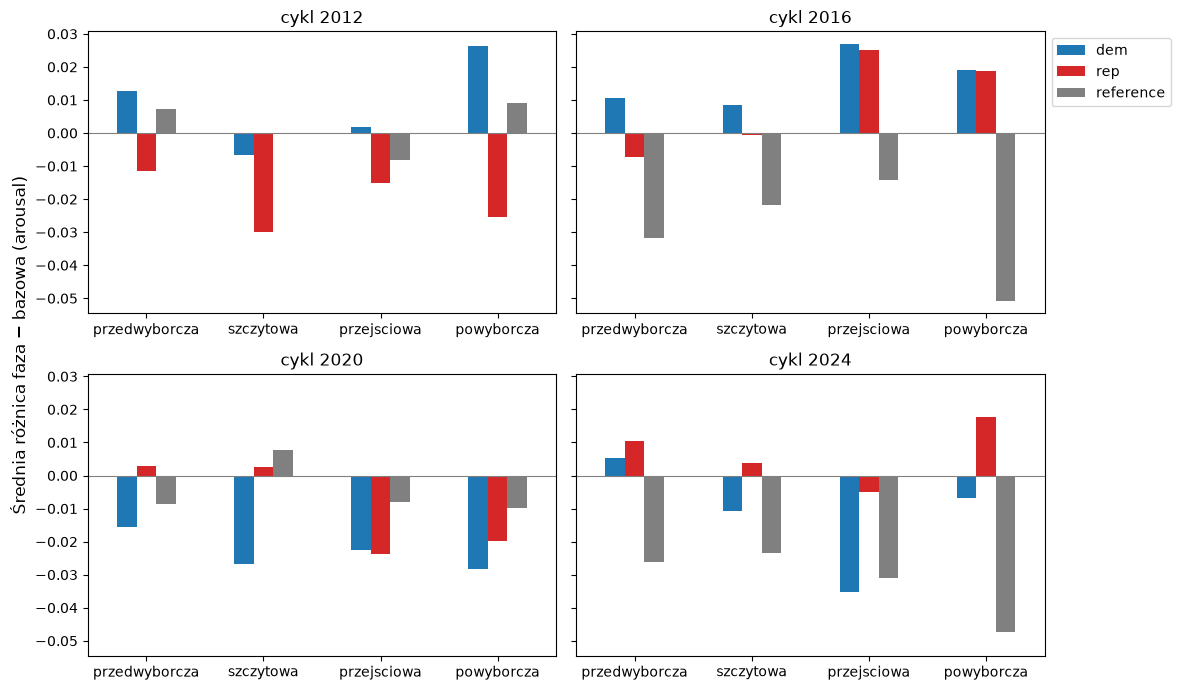

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharey=True)
for ax, cycle in zip(axes.ravel(), CYCLES):
    (comparison.xs(cycle, level="cycle").loc[PHASE_ORDER[1:], ["dem", "rep", "reference"]]
     .plot.bar(ax=ax, rot=0, legend=False, color=["tab:blue", "tab:red", "gray"]))
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.set_title(f"cykl {cycle}")
    ax.set_xlabel("")
axes[0, 1].legend(loc="upper left", bbox_to_anchor=(1, 1))
fig.supylabel(f"Średnia różnica faza − bazowa ({VARIABLE})")
plt.tight_layout()
plt.show()

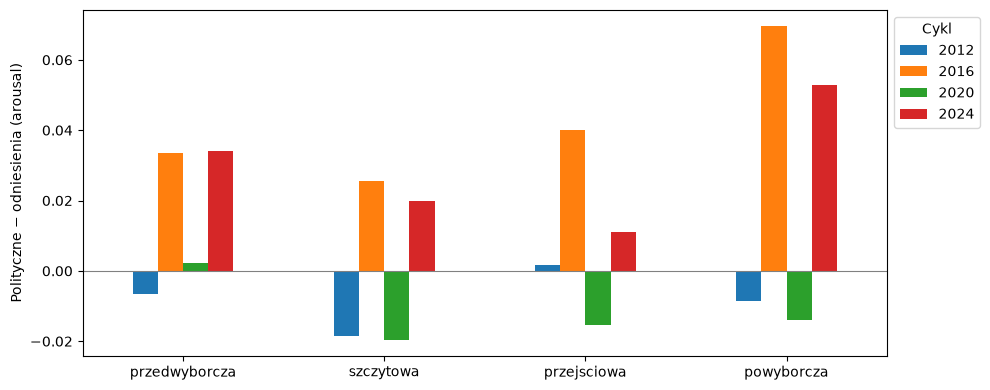

In [13]:
ax = comparison["political_minus_reference"].unstack("cycle").loc[PHASE_ORDER[1:]].plot.bar(figsize=(10, 4), rot=0)
ax.axhline(0, color="gray", linewidth=0.8)
ax.set_xlabel("")
ax.set_ylabel(f"Polityczne − odniesienia ({VARIABLE})")
ax.legend(title="Cykl", loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

In [14]:
reference_years = phase_stats[phase_stats["phase"] == "rok_referencyjny"]
reference_years.to_csv(RESULTS_DIR / "h2_reference_years.csv", index=False)
reference_means = reference_years.pivot_table(index="subreddit", columns="cycle", values="mean")
reference_means.round(4)

cycle,2014,2018,2022
subreddit,,,
languagelearning,0.6332,0.6609,0.6352
running,0.5985,0.5625,0.5706


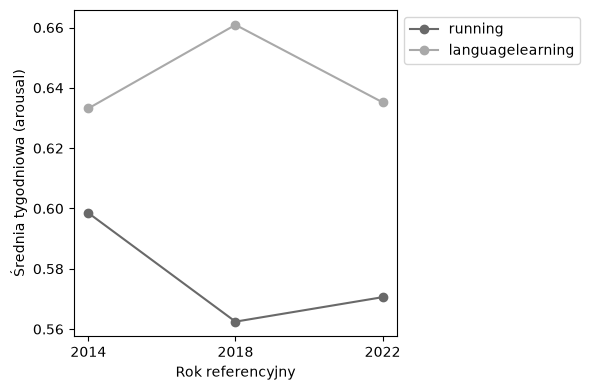

In [15]:
ax = reference_means.loc[REFERENCE_SUBREDDITS].T.plot(marker="o", figsize=(6, 4), color=["dimgray", "darkgray"])
ax.set_xticks(reference_means.columns)
ax.set_xlabel("Rok referencyjny")
ax.set_ylabel(f"Średnia tygodniowa ({VARIABLE})")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

## 7. Wykres roboczy: tydzień po tygodniu z fazami

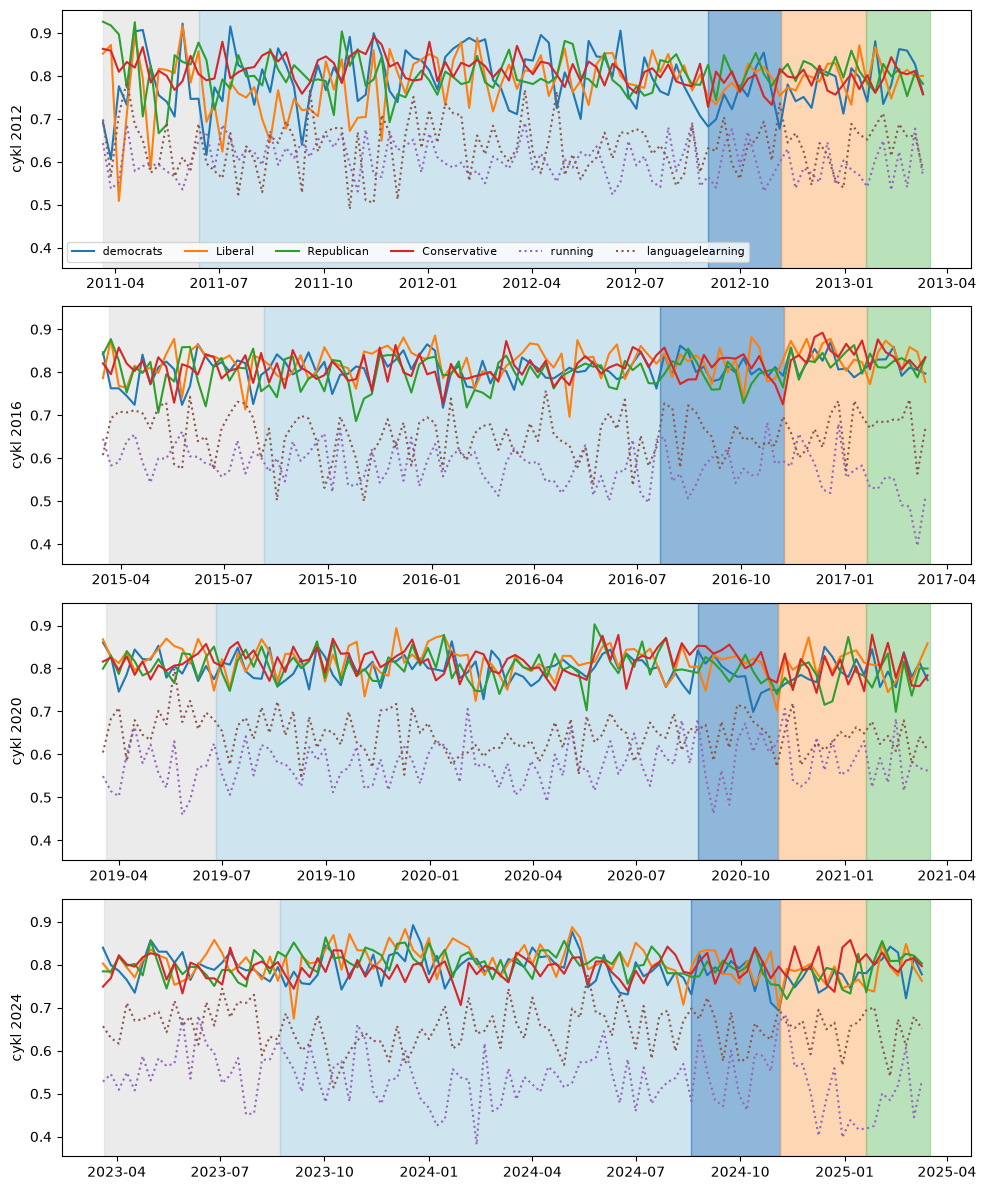

In [16]:
fig, axes = plt.subplots(len(CYCLES), 1, figsize=(10, 12), sharey=True)
for ax, cycle in zip(axes, CYCLES):
    for phase, start, end in PHASES[cycle]:
        ax.axvspan(pd.Timestamp(start), pd.Timestamp(end) + pd.Timedelta(days=1), color=PHASE_COLORS[phase], alpha=0.5)
    for subreddit in POLITICAL_SUBREDDITS + REFERENCE_SUBREDDITS:
        rows = weekly[(weekly["subreddit"] == subreddit) & (weekly["cycle"] == cycle)]
        ax.plot(rows["week_start"], rows[VARIABLE], label=subreddit, linestyle="-" if subreddit in POLITICAL_SUBREDDITS else ":")
    ax.set_ylabel(f"cykl {cycle}")
axes[0].legend(ncol=6, fontsize=8)
plt.tight_layout()
plt.show()